<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/hands-on-levels/L4_hypergraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Level 4: Hypergraph

**Goal:** in Level 3, links were **pairs** (one line joins 2 nodes). Here, links are **groups**: one link can join **many** nodes at once. We test whether groups, and especially **phrase groups** built from product text, help new products more than pairs.

**Same as Level 3:** every node is a **point on a map**, starts at a **random position**, and training moves the points so each product ends up **close to its own tags**.

**What changes:** only **who talks to whom**.

## Idea 1: pairs vs groups

A **hyperedge** is a **group**, like a **group chat**: every member hears everyone else at once.

| | Graph (Level 3) | Hypergraph (Level 4) |
|---|---|---|
| Link | **edge** = exactly 2 nodes | **hyperedge** = a group of **any** size |
| Example | repair shampoo — `dry hair` | {`dry hair`, hair mask, repair shampoo} |

**Why groups?** Linking 5 related things with pairs needs 10 separate lines, and nothing says they belong together. One group keeps them **as one unit**.

In the figure, the **phrase group "frizzy hair"** (solid bubble) holds every product whose text says "frizzy hair", including the **NEW shampoo**. So the new product is in the same group as old products tagged `dry hair`.

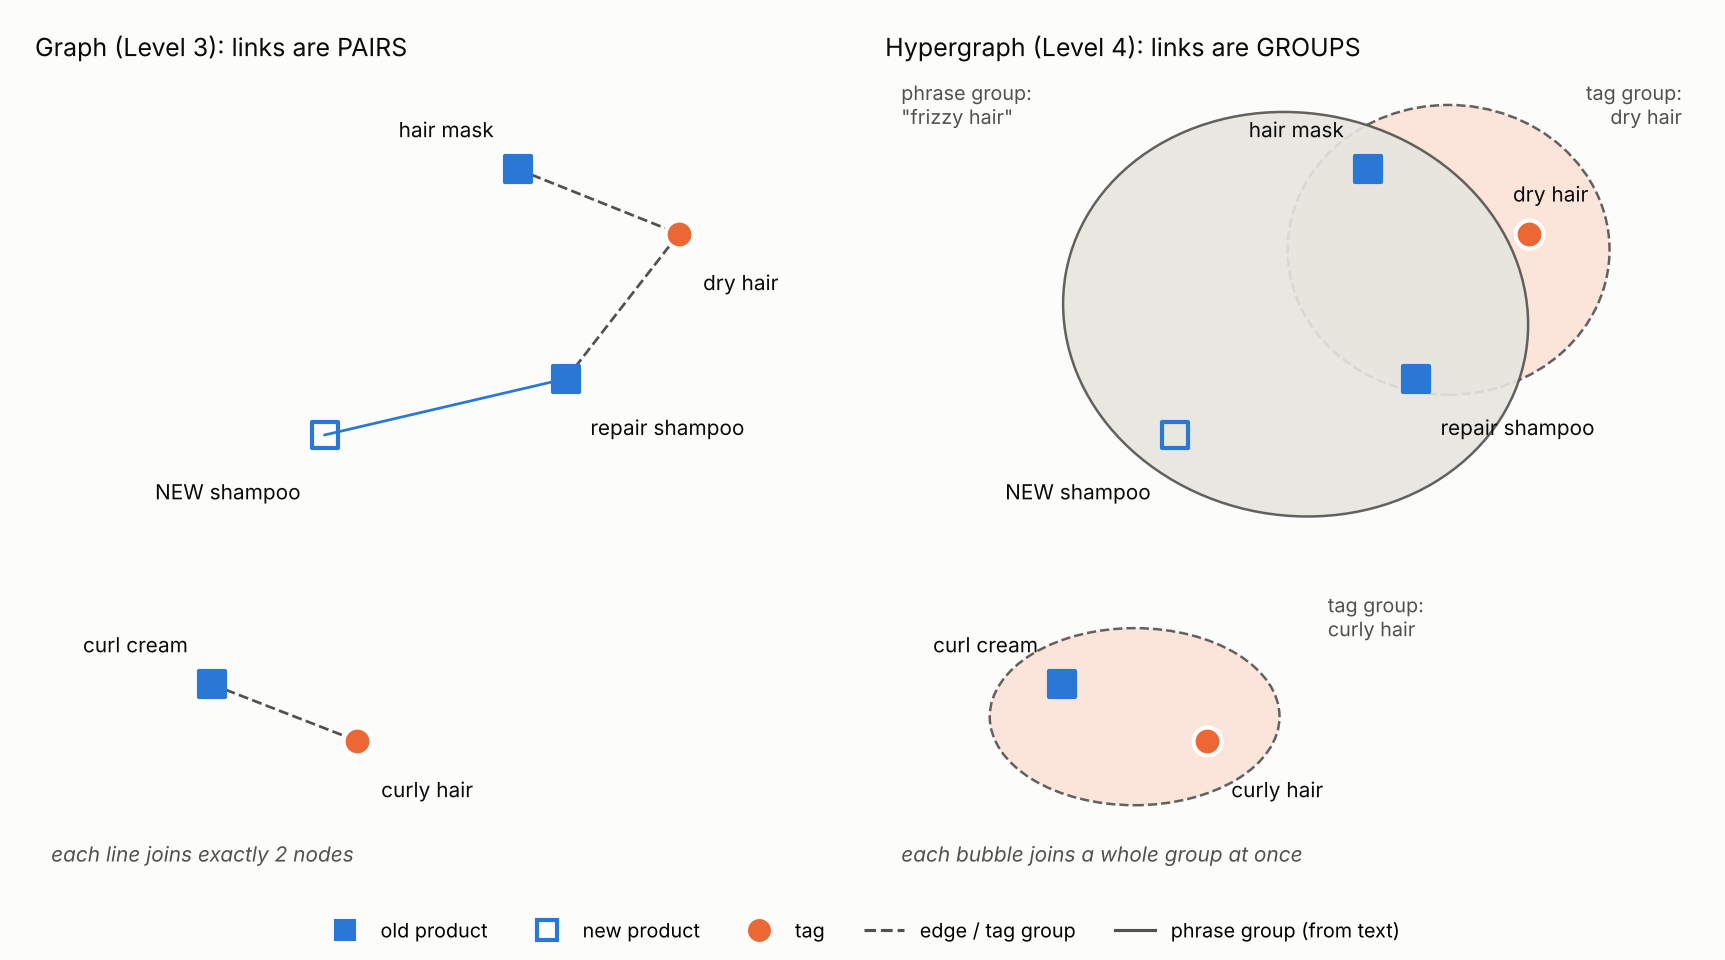

In [ ]:
#@title Figure 1: pairs vs groups
# (figure stored in this cell's output - don't run this cell)

## Idea 2: message passing in two steps

In Level 3, each node mixed with its neighbors **directly**. With groups, it takes **two steps**:

**Step 1: nodes → group.** Each group **averages** the positions of all its members → **one message per group**.

| Member | Position |
|---|---|
| hair mask | (0.15, 0.80) |
| repair shampoo | (0.30, 0.62) |
| `dry hair` | (0.80, 0.25) |
| **group message** = average | **(0.42, 0.56)** |

**Step 2: group → nodes.** Each node **combines the messages of every group it is in** → that is its new position.
- **In one group only** → it gets that group's message: e.g. **(0.42, 0.56)**.
- **In several groups** → it gets a **mix** of their messages, so it is pulled toward all of them at once:

  | NEW shampoo is in… | Message |
  |---|---|
  | phrase group "frizzy hair" | (0.42, 0.56) |
  | neighbor group | (0.20, 0.30) |
  | **new position ≈ mix** | **(0.31, 0.43)** |

**"Moves toward", not "jumps to":** as in Level 3, the final position is the **average over the layers** (start, layer 1, 2, 3). A node keeps part of its own start position, so it **moves toward** the messages instead of landing exactly on them (Figure 2, step 2: faded = old position).

**Big groups vs small groups:** the message is an **average**, so a group with 200 members sends a very "diluted" message, while a group of 5 similar products sends a sharp one. That's why we skip phrases shared by more than 200 products ("great product" says little).

**Link to the paper (Sec 3.5):** $D_v^{-1/2} H D_e^{-1} H^\top D_v^{-1/2}$ is exactly these two steps:
$H^\top$ + $D_e^{-1}$ = Step 1 (collect and average); $H$ = Step 2 (send back and mix); $D_v^{-1/2}$ = keeps nodes in many groups from getting too big. (CASTRA also multiplies each group by a learned weight $W$; here every group counts the same.)

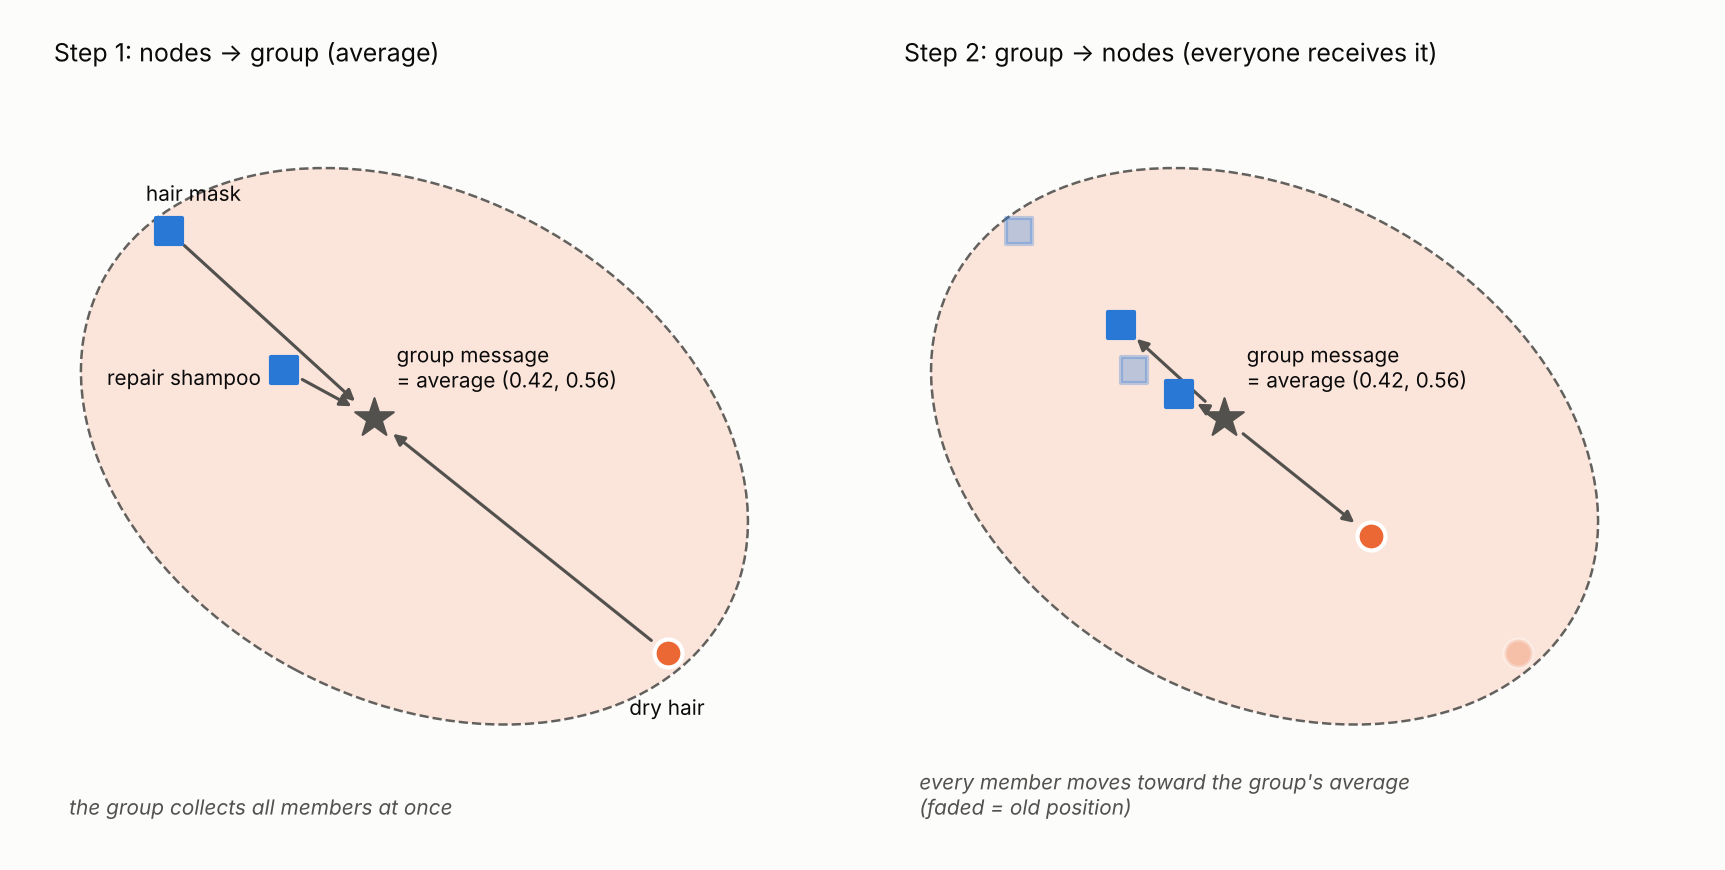

In [ ]:
#@title Figure 2: message passing in two steps
# (figure stored in this cell's output - don't run this cell)

## Idea 3: three kinds of groups

**Which groups to make is a design choice**, written in code. A hypergraph is only **nodes + groups**: any set of nodes that **share something** can be a group. For this tutorial we choose three kinds:

| Group | How many | Members | Uses tags? | Example |
|---|---|---|---|---|
| **Tag group** | **one per tag** (39) | the tag + all **training** products that have it | yes (train only) | {`dry hair`, hair mask, argan serum, repair shampoo} |
| **Neighbor group** | **one per product** (~1,700) | the product + its 5 most similar **training** products (text) | no | {NEW shampoo + 5 similar old products} |
| **Phrase group** | **one per shared phrase** | all products (old **and** new) whose text contains the same adjective+noun phrase (spaCy) | no | {all products saying "frizzy hair"} |

### How a neighbor group is made (the Level 2 neighbors, as a group)

For **each product**, old or new:
1. Take its **BERT text vector** (Level 1).
2. Compare it with every **training** product (cosine similarity).
3. Keep the **5 most similar** (never itself).
4. Group = **the product + those 5**.

**Example:** NEW "Argan Oil Repair Shampoo"

| Training product | Similarity |
|---|---|
| Repair shampoo for damaged hair | 0.82 ✓ |
| Argan oil hair mask | 0.78 ✓ |
| Moisturizing shampoo | 0.75 ✓ |
| Anti-frizz conditioner | 0.71 ✓ |
| Argan oil serum | 0.70 ✓ |
| Red nail polish | 0.12 ✗ |

→ neighbor group = {NEW shampoo + the 5 ✓ products}

### How a NEW product joins

It has **no tags**, so it is in **no tag group**. But it has **text**, so it joins **neighbor** and **phrase** groups. Its old group-mates **are** in tag groups, so through them it hears about tags.

**Example path:** `dry hair` → (tag group) → hair mask → (phrase group "frizzy hair") → **NEW shampoo**

### Other groups you could add

Any shared property works, e.g. a **brand group** (same brand), a **sentiment group** (reviews praise the same thing, `hair:+`), or **review-phrase groups** (phrases from reviews instead of product text). CASTRA makes yet another choice: one group per (product, tag) pair, {product, tag, phrase, sentiment, context}.

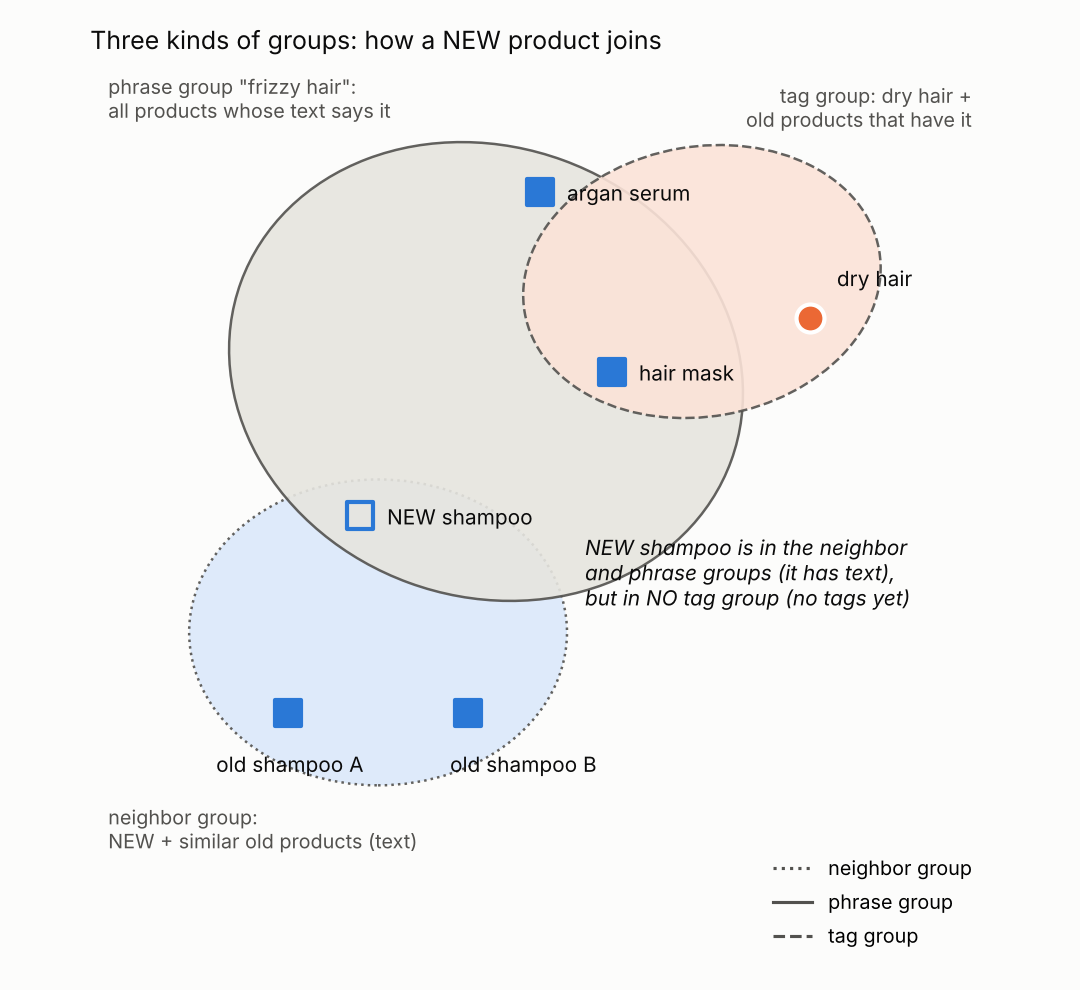

In [ ]:
#@title Figure 3: three kinds of groups
# (figure stored in this cell's output - don't run this cell)

## Idea 4: training is the same as Level 3

| | Level 3 | Level 4 |
|---|---|---|
| Start positions | random | random |
| Message passing | over **pairs** (edges) | over **groups** (2 steps) |
| Training rule (BPR) | product closer to its **true** tag than to a **random** tag | same |
| Score | dot product → top 10 tags | same |

So in the code, we **reuse** Level 3's `LightGCN` model and `train_lightgcn` function. Only the matrix `A` ("who talks to whom") is built differently, from the groups.

setup, the same as Level 1 (data, tags, split)

In [1]:
import json, gzip, os, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

# 1) Download the two files (only the first time)
base = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw"
for url, name in [(f"{base}/meta_categories/meta_All_Beauty.jsonl.gz", "meta.jsonl.gz"),
                  (f"{base}/review_categories/All_Beauty.jsonl.gz", "reviews.jsonl.gz")]:
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)

# 2) Read the first 2,000 products
products = []
for line in gzip.open("meta.jsonl.gz", "rt"):
    products.append(json.loads(line))
    if len(products) == 2000:
        break

# 3) Reviews and first-review time of those products
reviews = {p["parent_asin"]: [] for p in products}
first_time = {}
for line in gzip.open("reviews.jsonl.gz", "rt"):
    r = json.loads(line)
    a = r["parent_asin"]
    if a in reviews:
        reviews[a].append(r["text"])
        first_time[a] = min(first_time.get(a, r["timestamp"]), r["timestamp"])

# 4) Tags = values of seller attributes, minus identifiers and junk keys
SKIP = {"Brand", "Manufacturer", "UPC", "Product Dimensions", "Item model number",
        "Date First Available", "Item Weight", "Package Dimensions",
        "Is Discontinued By Manufacturer", "Unit Count", "Number of Items",
        "Age Range (Description)", "Mounting Type", "Installation Type",
        "Package Information", "Extension Length"}

def all_tags_of(p):
    tags = []
    for key, value in p["details"].items():
        if key in SKIP or not isinstance(value, str):
            continue
        for v in value.split(","):                 # "Oily, Dry" -> two tags
            v = v.strip().lower()
            if v and v != "all":                   # "suits everyone" is not a tag
                tags.append(f"{key}: {v}")
    return tags

counts = Counter(t for p in products for t in all_tags_of(p))
candidate_tags = sorted(t for t, c in counts.items() if c >= 20)   # tags on >= 20 products
products = [p for p in products if set(all_tags_of(p)) & set(candidate_tags)]
n, m = len(products), len(candidate_tags)

# 5) Answer key Y: Y[k, j] = 1 if product k has tag j
Y = np.array([[t in all_tags_of(p) for t in candidate_tags] for p in products], dtype=float)

# 6) Split by time: oldest 70% train, next 15% validation, newest 15% test (= new products)
t = np.array([first_time.get(p["parent_asin"], np.inf) for p in products])
order = np.argsort(t)
train_idx = order[: int(0.70 * n)]
val_idx   = order[int(0.70 * n): int(0.85 * n)]
test_idx  = order[int(0.85 * n):]
print(n, "products |", m, "tags |", len(train_idx), "train /", len(val_idx), "val /", len(test_idx), "test")

1057 products | 35 tags | 739 train / 159 val / 159 test


metric, BERT vectors and the Level 1 baselines (for comparison)

In [2]:
def evaluate(scores, products_idx, K=10):
    """scores: (products, tags), higher = more likely -> Precision@K, Recall@K, NDCG@K."""
    truth = Y[products_idx]
    top = np.argsort(-scores, axis=1)[:, :K]                    # the K best tags per product
    hits = np.take_along_axis(truth, top, axis=1)               # 1 where a recommended tag is correct
    n_true = truth.sum(axis=1)
    discount = 1 / np.log2(np.arange(2, K + 2))                 # position 1 counts most
    ideal = np.array([discount[:int(min(nt, K))].sum() for nt in n_true])
    return {"Precision@10": (hits.sum(axis=1) / K).mean(),
            "Recall@10":    (hits.sum(axis=1) / n_true).mean(),
            "NDCG@10":      ((hits * discount).sum(axis=1) / ideal).mean()}

# BERT vectors for products and tags
encoder = SentenceTransformer("all-MiniLM-L6-v2")
texts = [p["title"] + " " + " ".join(p["features"] + p["description"]) for p in products]
Z_prod = encoder.encode(texts, normalize_embeddings=True)          # (n, 384)
Z_tag  = encoder.encode(candidate_tags, normalize_embeddings=True) # (m, 384)

# Level 1 baselines
results = {}
rng = np.random.default_rng(0)
results["Random"] = evaluate(rng.random((len(test_idx), m)), test_idx)
results["Popularity"] = evaluate(np.tile(Y[train_idx].sum(axis=0), (len(test_idx), 1)), test_idx)
results["Text similarity"] = evaluate(Z_prod[test_idx] @ Z_tag.T, test_idx)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [3]:

# ===== Level 2: borrow tags from the most similar TRAINING products =====
K_NEIGHBORS = 5

# 1) Similarity of every test product to every training product (BERT vectors from Level 1)
sims = Z_prod[test_idx] @ Z_prod[train_idx].T            # (test products, train products)

# 2) The 5 most similar training products for each test product
top = np.argsort(-sims, axis=1)[:, :K_NEIGHBORS]          # positions inside train_idx
neighbors = train_idx[top]                                # real product numbers, (test, 5)
neighbor_sims = np.take_along_axis(sims, top, axis=1)     # their similarity scores, (test, 5)

# 3a) Vote: each tag's score = number of neighbors that have it
#     Y[neighbors] is (test, 5, tags) -> sum over the 5 neighbors -> (test, tags)
votes = Y[neighbors].sum(axis=1)
results["Neighbors (vote)"] = evaluate(votes, test_idx)

# 3b) Weighted vote: closer neighbors count more (each neighbor's tags x its similarity)
weighted = (neighbor_sims[:, :, None] * Y[neighbors]).sum(axis=1)
results["Neighbors (weighted)"] = evaluate(weighted, test_idx)

table = pd.DataFrame(results).T.round(3)
table

,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636


graph builder, model and training

In [4]:
import torch
import torch.nn.functional as F

# Use the GPU if Colab has one, otherwise the CPU (this small graph is fast on CPU too)
device = "cpu"

# ------------------------------------------------------------------
# Node numbering: one number per node in the graph
#   products = 0 .. n-1        (e.g. product 5 is node 5)
#   tags     = n .. n+m-1      (e.g. tag 0 is node n, tag 1 is node n+1, ...)
# ------------------------------------------------------------------
N_NODES = n + m


def build_graph(extra_pairs=None):
    """Build the graph's EDGES (the lines on the map). They come from the DATA, not chance.
    - product <-> tag edges: every TRAINING product with each of its true tags
    - extra_pairs (used in 3b): product <-> product edges from text similarity
    Returns the graph as a normalized 'adjacency matrix' A:
    A[i, j] > 0 means node i receives information from node j."""

    # 1) All (train product, true tag) pairs -> one edge each
    rows, cols = np.where(Y[train_idx] == 1)        # rows = position in train_idx, cols = tag number
    prod = train_idx[rows]                          # real product node numbers
    tag = n + cols                                  # tag node numbers (tags start at n)

    # 2) Edges go both ways: product -> tag AND tag -> product
    #    (so information flows in both directions during message passing)
    src, dst = [prod, tag], [tag, prod]             # src = sender, dst = receiver

    # 3) (3b only) add product <-> product edges, also both ways
    if extra_pairs is not None:
        a, b = extra_pairs
        src += [a, b]; dst += [b, a]
    src, dst = np.concatenate(src), np.concatenate(dst)

    # 4) Normalize: a node with many edges (e.g. a popular tag on 500 products) would
    #    otherwise get a huge sum of messages. Each edge's weight = 1 / sqrt(deg_sender * deg_receiver)
    deg = np.bincount(src, minlength=N_NODES).astype(float)       # number of edges per node
    w = 1 / np.sqrt(deg[src] * deg[dst])

    # 5) Store A as a SPARSE matrix: only the edges are stored, not the millions of zeros
    A = torch.sparse_coo_tensor(
        torch.tensor(np.vstack([dst, src])),        # positions: (receiver, sender)
        torch.tensor(w, dtype=torch.float32),       # values: the edge weights
        (N_NODES, N_NODES)).coalesce()
    return A.to(device)


class LightGCN(torch.nn.Module):
    """The model. Its ONLY learnable part is the start position (vector) of every node."""

    def __init__(self, n_nodes, dim=64, n_layers=3):
        super().__init__()
        # Idea 1: every node gets a vector of 64 numbers = its position on the map
        self.emb = torch.nn.Embedding(n_nodes, dim)
        torch.nn.init.normal_(self.emb.weight, std=0.1)    # random start positions
        self.n_layers = n_layers

    def forward(self, A):
        # Idea 2: message passing = each node moves toward its connections
        x = self.emb.weight                                # layer 0: the start positions
        layers = [x]
        for _ in range(self.n_layers):                     # 3 rounds of mixing
            x = torch.sparse.mm(A, x)                      # each node = weighted mix of its neighbors
            layers.append(x)
        # Final position = average of layer 0, 1, 2, 3
        # (keeps some of the node's own position + what it learned from 1, 2, 3 steps away)
        return torch.stack(layers).mean(dim=0)             # (N_NODES, 64)


def train_lightgcn(A, epochs=300, verbose=True):
    """Idea 3: adjust the start positions so each product is closer to its TRUE tags
    than to RANDOM tags (the BPR rule). Returns the final positions of all nodes."""
    torch.manual_seed(0); np.random.seed(0)                # same result every run
    model = LightGCN(N_NODES).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)   # Adam nudges the positions

    # The training examples: every (train product, true tag) pair
    rows, cols = np.where(Y[train_idx] == 1)
    pos_prod = torch.tensor(train_idx[rows], device=device)      # products
    pos_tag = torch.tensor(n + cols, device=device)              # their true tags

    for epoch in range(1, epochs + 1):
        # For each pair, pick one RANDOM tag to compare against (e.g. "nail polish")
        neg_tag = torch.randint(n, n + m, pos_tag.shape, device=device)

        E = model(A)                                             # current final positions

        # Score = dot product = how close two points are (bigger = closer)
        s_pos = (E[pos_prod] * E[pos_tag]).sum(dim=1)            # product vs TRUE tag
        s_neg = (E[pos_prod] * E[neg_tag]).sum(dim=1)            # product vs RANDOM tag

        # BPR loss: small when s_pos is much bigger than s_neg (rule respected),
        #           large when the random tag is as close as the true one (rule broken)
        loss = -F.logsigmoid(s_pos - s_neg).mean()

        # Adam: compute how to move every start position to reduce the loss, then move it
        opt.zero_grad(); loss.backward(); opt.step()

        # Every 50 epochs: check progress on VALIDATION products (not used for training)
        if verbose and epoch % 50 == 0:
            with torch.no_grad():                                # just measuring, no learning
                E = model(A)
                val = evaluate((E[val_idx] @ E[n:].T).cpu().numpy(), val_idx)["NDCG@10"]
            print(f"epoch {epoch}: loss {loss.item():.4f}, validation NDCG@10 {val:.3f}")

    # After training: the final positions of all nodes
    with torch.no_grad():
        E = model(A)
    return E


def lightgcn_scores(E, idx):
    """Score every tag for the products in idx = how close each tag is to each product.
    E[idx]: product positions (products, 64);  E[n:]: tag positions (tags, 64)
    Result: (products, tags) score table -> evaluate() keeps the top 10 per product."""
    return (E[idx] @ E[n:].T).cpu().numpy()

3a, the plain graph

In [5]:
A_plain = build_graph()
E_plain = train_lightgcn(A_plain)
results["LightGCN (plain)"] = evaluate(lightgcn_scores(E_plain, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

/tmp/ipykernel_1959/4004397956.py:43: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  A = torch.sparse_coo_tensor(


epoch 50: loss 0.1060, validation NDCG@10 0.123
epoch 100: loss 0.0882, validation NDCG@10 0.167
epoch 150: loss 0.0829, validation NDCG@10 0.157
epoch 200: loss 0.0866, validation NDCG@10 0.212
epoch 250: loss 0.0752, validation NDCG@10 0.182
epoch 300: loss 0.0739, validation NDCG@10 0.168


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203


3b, the graph with text neighbors

In [6]:
# Every product -> its 5 most similar TRAINING products (never itself)
sims_all = Z_prod @ Z_prod[train_idx].T                  # (all products, train products)
sims_all[train_idx, np.arange(len(train_idx))] = -np.inf # a train product is not its own neighbor
top5 = np.argsort(-sims_all, axis=1)[:, :5]
pairs = (np.repeat(np.arange(n), 5), train_idx[top5].ravel())   # (product, neighbor) pairs

A_text = build_graph(extra_pairs=pairs)
E_text = train_lightgcn(A_text)
results["LightGCN + text neighbors"] = evaluate(lightgcn_scores(E_text, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

epoch 50: loss 0.1813, validation NDCG@10 0.722
epoch 100: loss 0.1516, validation NDCG@10 0.730
epoch 150: loss 0.1477, validation NDCG@10 0.730
epoch 200: loss 0.1394, validation NDCG@10 0.736
epoch 250: loss 0.1266, validation NDCG@10 0.732
epoch 300: loss 0.1299, validation NDCG@10 0.735


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666


find phrases with spaCy

In [7]:
!python -m spacy download en_core_web_sm -q
import spacy
from collections import Counter
nlp = spacy.load("en_core_web_sm", disable=["ner"])

def phrases_of(doc):
    """Adjective + noun pairs, e.g. 'frizzy hair', 'long lasting' -> {'frizzy hair', ...}"""
    return {f"{t.lemma_.lower()} {t.head.lemma_.lower()}"
            for t in doc if t.dep_ == "amod" and t.head.pos_ == "NOUN" and t.is_alpha}

# Parse the product text (title + features + description) of ALL products: new ones have text too
product_phrases = [phrases_of(doc) for doc in nlp.pipe([t[:1000] for t in texts], batch_size=64)]

# Keep phrases shared by 3..200 products: rarer ones connect nothing, more common ones are too generic
phrase_count = Counter(q for s in product_phrases for q in s)
kept_phrases = sorted(q for q, c in phrase_count.items() if 3 <= c <= 200)
print(len(phrase_count), "phrases found ->", len(kept_phrases), "kept as groups")
print("most shared:", [q for q, _ in phrase_count.most_common(10)])

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
1537 phrases found -> 38 kept as groups
most shared: ['high quality', 'synthetic fiber', 'human hair', 'costume party', 'fine line', 'damage hair', 'essential oil', 'full head', 'own hair', 'adjustable strap']


turn a list of groups into the propagation matrix

In [8]:
import scipy.sparse as sp

def build_hypergraph(hyperedges):
    """hyperedges: list of groups, each a list of node numbers.
    Returns A = Dv^-1/2 H De^-1 H^T Dv^-1/2  (the paper's formula, with all group weights = 1),
    which plays the same role as A in Level 3: 'who talks to whom, and how strongly'."""
    # Incidence matrix H: rows = nodes, columns = groups, 1 = node is in the group
    rows = [v for e in hyperedges for v in e]
    cols = [g for g, e in enumerate(hyperedges) for _ in e]
    H = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(N_NODES, len(hyperedges)))

    Dv = np.asarray(H.sum(axis=1)).ravel()                 # how many groups each node is in
    De = np.asarray(H.sum(axis=0)).ravel()                 # how many nodes each group has
    dv = np.where(Dv > 0, 1 / np.sqrt(np.maximum(Dv, 1)), 0.0)

    # nodes -> group (average: / De), then group -> nodes, normalized on both sides by Dv
    A = (sp.diags(dv) @ H @ sp.diags(1 / De) @ H.T @ sp.diags(dv)).tocoo()
    A = torch.sparse_coo_tensor(torch.tensor(np.vstack([A.row, A.col]), dtype=torch.long),
                                torch.tensor(A.data, dtype=torch.float32), (N_NODES, N_NODES)).coalesce()
    return A.to(device)

# --- The groups ---
# 1) Tag groups: tag node + all TRAIN products that have the tag
tag_groups = [[n + j] + list(train_idx[Y[train_idx, j] == 1]) for j in range(m)]

# 2) Neighbor groups: each product + its 5 most similar TRAIN products (not itself)
sims_all = Z_prod @ Z_prod[train_idx].T
sims_all[train_idx, np.arange(len(train_idx))] = -np.inf
top5 = np.argsort(-sims_all, axis=1)[:, :5]
neighbor_groups = [[k] + list(train_idx[top5[k]]) for k in range(n)]

# 3) Phrase groups: all products (old AND new) whose text contains the phrase
phrase_groups = [[k for k in range(n) if q in product_phrases[k]] for q in kept_phrases]

print(len(tag_groups), "tag groups |", len(neighbor_groups), "neighbor groups |", len(phrase_groups), "phrase groups")

35 tag groups | 1057 neighbor groups | 38 phrase groups


## 4a: Hypergraph with tag groups + neighbor groups

**Goal:** test whether **groups** help more than **pairs**, using exactly the **same information** as Level 3b.

| | Level 3b (graph) | 4a (hypergraph) |
|---|---|---|
| Tag information | pairs: hair mask — `dry hair`, argan serum — `dry hair`, … | **one group per tag**: {`dry hair`, hair mask, argan serum, …} |
| Text neighbors | pairs: NEW shampoo — each of its 5 neighbors | **one group per product**: {NEW shampoo + its 5 neighbors} |
| Phrases | no | no |

**What the code does:**
1. `build_hypergraph(tag_groups + neighbor_groups)`: builds the "who talks to whom" matrix `A` from the groups (Step 1: each group averages its members; Step 2: each node mixes its groups' messages).
2. `train_lightgcn(A_4a)`: the **same** model and training as Level 3 (random start positions + the BPR rule). Only `A` is new.
3. `evaluate(...)` on the **test** products (new products) → a new row in the results table.

**What to compare:** 4a vs **Level 3b (NDCG 0.666, Recall 0.901)**.
- **4a higher** → grouping itself helps.
- **About the same** → groups and pairs carry the same information here.
- **4a lower** → big groups (e.g. a popular tag with hundreds of products) may **dilute** the messages.

In [9]:
A_4a = build_hypergraph(tag_groups + neighbor_groups)
E_4a = train_lightgcn(A_4a)                        # same model and training as Level 3
results["Hypergraph (tags + neighbors)"] = evaluate(lightgcn_scores(E_4a, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

epoch 50: loss 0.2556, validation NDCG@10 0.688
epoch 100: loss 0.2050, validation NDCG@10 0.725
epoch 150: loss 0.1925, validation NDCG@10 0.735
epoch 200: loss 0.1832, validation NDCG@10 0.725
epoch 250: loss 0.1693, validation NDCG@10 0.722
epoch 300: loss 0.1722, validation NDCG@10 0.722


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666
Hypergraph (tags + neighbors),0.175,0.911,0.658


## 4b: + phrase groups

**Goal:** test whether **phrases from the product text** add new information, beyond what 4a already has.

**What changes from 4a:** only one thing, we **add phrase groups**.

| | 4a | 4b |
|---|---|---|
| Tag groups | ✓ | ✓ |
| Neighbor groups | ✓ | ✓ |
| **Phrase groups** | ✗ | **✓** |

**Phrase group** = all products (old **and** new) whose text contains the same adjective+noun phrase, found by spaCy.
Example: {all products saying "frizzy hair"}, or {all products saying "long lasting"}

**Why it might help a new product:** its 5 text neighbors may miss a useful clue. A phrase group can connect it to **other** old products that share an exact phrase:

    NEW shampoo ─(phrase "frizzy hair")─ hair mask ─(tag group)─ dry hair

**What the code does:**
1. `build_hypergraph(tag_groups + neighbor_groups + phrase_groups)`: same as 4a, plus the phrase groups.
2. `train_lightgcn(A_4b)`: the same model and training.
3. `evaluate(...)` on the **test** (new) products → a new row in the table.

**What to compare:** 4b vs **4a** (same groups, minus phrases).
- **4b higher** → shared phrases carry useful information for tagging (supports CASTRA's idea of phrase nodes).
- **About the same** → the text neighbors already capture what the phrases say.
- **4b lower** → phrase groups add noise (e.g. generic phrases like "great product" link unrelated products).

In [10]:
A_4b = build_hypergraph(tag_groups + neighbor_groups + phrase_groups)
E_4b = train_lightgcn(A_4b)
results["Hypergraph + phrases"] = evaluate(lightgcn_scores(E_4b, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

epoch 50: loss 0.2562, validation NDCG@10 0.682
epoch 100: loss 0.2053, validation NDCG@10 0.714
epoch 150: loss 0.1929, validation NDCG@10 0.722
epoch 200: loss 0.1837, validation NDCG@10 0.717
epoch 250: loss 0.1698, validation NDCG@10 0.710
epoch 300: loss 0.1727, validation NDCG@10 0.715


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666
Hypergraph (tags + neighbors),0.175,0.911,0.658
Hypergraph + phrases,0.175,0.911,0.658


In [11]:
print("phrases kept as groups:", len(kept_phrases))
print("phrase groups:", len(phrase_groups), "| average size:",
      round(np.mean([len(g) for g in phrase_groups]), 1) if phrase_groups else 0)

# Do phrase groups reach the NEW (test) products?
in_phrase = set(k for g in phrase_groups for k in g)
print("test products in at least one phrase group:", sum(k in in_phrase for k in test_idx), "of", len(test_idx))

# Is the 4b graph really different from 4a?
print("connections in A_4a:", A_4a._nnz(), "| in A_4b:", A_4b._nnz())
print("examples:", kept_phrases[:10])

phrases kept as groups: 38
phrase groups: 38 | average size: 4.3
test products in at least one phrase group: 23 of 159
connections in A_4a: 73844 | in A_4b: 74422
examples: ['adjustable strap', 'black woman', 'brazilian hair', 'brazilian wig', 'costume party', 'daily use', 'damage hair', 'dark circle', 'different color', 'dramatic volume']



**Goal:** see whether **groups** (hypergraph) beat **pairs** (graph), and whether **phrase groups** from product text help new products.

| Method | Precision@10 | Recall@10 | NDCG@10 |
|---|---|---|---|
| LightGCN + text neighbors (Level 3b, pairs) | 0.173 | 0.901 | **0.666** |
| Hypergraph: tags + neighbors (4a, groups) | **0.175** | **0.911** | 0.658 |
| Hypergraph + phrases (4b) | 0.175 | 0.911 | 0.658 |

**1. Groups ≈ pairs (4a vs 3b).** With the **same information**, the hypergraph performs about the same as the graph: slightly higher Recall, slightly lower NDCG, both tiny differences. Organizing links as groups doesn't help by itself here.

**2. Phrase groups changed nothing (4b vs 4a).** Only **38 small phrase groups** were found (product texts are mostly short titles), and they reach just **23 of 159** new products. Too little to affect the results.

**3. Training behaved normally.** Validation NDCG rises to ~**0.72 by epoch 150** and then stays flat, so the model converged; more epochs wouldn't help.

**Takeaway:** a hypergraph is only as useful as the groups you give it. With short product text, phrase groups are rare, so the hypergraph ends up no better than the simpler graph. (CASTRA's phrase nodes depend on rich text too.)

**Best so far:** NDCG@10 ≈ **0.66**, Recall@10 ≈ **0.91** (graph or hypergraph with text neighbors).